# Imports

In [1]:
import seaborn as sns
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, Normalize
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Load data

In [2]:
def replace_negatives_and_zeros_with_row_max(df):
    """
    Replaces negative numbers and zeros in each row of a DataFrame with the maximum value of that row.

    Args:
        df (pd.DataFrame): Input DataFrame.

    Returns:
        pd.DataFrame: DataFrame with modified values.
    """
    # Add a count of how many values have a zero
    count_zero = df.apply(lambda row: (row == 0).sum(), axis=1)
    print("Number of values changed:", count_zero.sum())
    
    # Iterate through each row
    for index, row in df.iterrows():
        max_val = row.max()
        df.loc[index] = row.apply(lambda x: max_val if x <= 0 else x)

    return df

def replace_negatives_and_zeros_with_row_and_column_max(df):
    """
    Replaces negative numbers and zeros in each row and column of a DataFrame with the maximum value of that row and column.

    Args:
        df (pd.DataFrame): Input DataFrame.

    Returns:
        pd.DataFrame: DataFrame with modified values.
    """
    # First, find the max values for each row and column before modifying
    row_max_values = df.max(axis=1)
    column_max_values = df.max()
    print("Acid Chlorides")
    print(row_max_values)
    print("\nAmines")
    print(column_max_values)
    
    # Count the number of zeros and negative values
    count_zero_negative = df.apply(lambda row: ((row == 0) | (row <= 0)).sum(), axis=1)
    print("Number of values changed:", count_zero_negative.sum())
    
    # Iterate through each row
    for index, row in df.iterrows():
        row_max = row_max_values[index]
        
        # Replace zeros and negatives with the max value between row max and corresponding column max
        # df.loc[index] = row.apply(lambda x, col=row: max(row_max, column_max_values[col.name]) if x <= 0 else x)
        for col in df.columns:
            if df.loc[index, col] <= 0:
                print(f'replacing amine = {col} and acid chloride = {index} by', row_max, column_max_values[col], max(row_max, column_max_values[col]))
                df.loc[index, col] = max(row_max, column_max_values[col])

    return df



In [3]:
all_df = pd.read_csv("data/all_raw_data_with_labels.csv", index_col=0)
all_df.rename(columns={"2": "Controls"}, inplace=True)
train_df = all_df.iloc[:32, :35]
print(train_df.shape)

(32, 35)


In [4]:
# Remove the "Acid Labels" column and "Amine Labels" row
train_df = train_df.drop(columns=['Acid Labels'])
train_df = train_df.drop(index=['Amine Labels'])
train_df

,tertbutylamine,Controls,4-fluoroaniline,p-anisidine,aniline,"2,4,6-trimethylaniline",4-heptylaniline,"2,6-diisopropylaniline",dicyclohexylamine,4-hexylaniline,...,p-toluidine,m-toluidine,N-isopropylcyclohexanamine,o-anisidine,triphenylmethanamine,"2,6-dimethylaniline","tertbutyl-3,5-dimethylpiperazin-1-carboxylate",3-anilinopropionitrile,2-fluoroaniline,3-methoxyaniline
4-fluorobenzoyl chloride-average,521.942558,11.763533,19.593600,425.146340,17.876277,16.011251,65.730510,12.642810,16.539027,67.061713,...,65.038011,29.568728,7.907942,38.572172,7.055067,6.090463,16.732790,6.521297,7.587329,14.548795
benzoyl chloride,4.928887,7.017544,20.539425,290.909091,15.978581,17.139130,50.760668,8.761154,11.727137,52.389381,...,64.000000,25.374214,13.096060,24.406085,8.936616,8.084680,8.102404,7.165362,7.804959,11.379956
4-tertbutyl benzoyl chloride,2.005995,3.638350,7.999518,89.411564,8.106494,8.786975,26.826229,3.798261,4.076398,28.022599,...,21.139281,11.407964,5.497678,10.457711,4.830786,4.901179,4.849725,3.538230,4.310531,6.260919
"2,4-difluorobenzoyl chloride",30.750751,40.345423,323.217031,1462.857143,436.447958,146.420664,557.948718,44.511715,90.326241,727.047216,...,1024.000000,494.177215,106.222781,336.130581,72.908024,98.773714,189.226765,91.454813,73.306799,260.423164
4-trifluoromethylbenzoyl chloride,41.638791,39.128978,172.307692,0.000000,65.367281,45.714286,192.876712,40.593792,82.212661,283.181818,...,975.238095,397.137069,210.507726,554.218134,192.682129,226.171755,345.433466,202.392919,184.947093,204.937388
4-phenylbenzoyl chloride,5.654085,4.505172,13.551685,212.067260,13.364486,11.570127,51.055276,6.833346,8.758108,51.034483,...,56.203082,24.782790,8.329712,21.071030,5.338186,4.355688,14.497048,4.122270,5.216105,9.082512
thiophene-2-carbonyl chloride,5.240550,16.838853,12.036557,115.898968,7.563419,9.642732,19.971276,13.464360,11.722428,23.360419,...,25.153746,13.062290,22.512424,10.704220,23.486239,23.144514,14.351013,24.208457,23.217015,21.816947
2-naphthoyl chloride,4.257202,5.887430,15.643965,199.315445,15.845143,13.864365,69.241122,6.376956,11.872184,70.190921,...,64.649982,26.251298,9.993060,27.485311,6.524925,3.465254,5.251694,4.596741,6.262273,14.027989
p-anisoyl chloride,1.672351,4.708404,4.302569,54.786981,4.205155,4.415322,14.576116,3.931116,6.563238,11.164686,...,9.947711,4.485183,5.763878,4.092517,7.887213,6.572477,2.224113,5.023844,8.279060,3.001917
pivaloyl chloride,0.720721,3.740117,35.616633,458.594104,33.371071,2.870455,154.840353,3.244340,6.218518,119.369234,...,90.150538,43.121873,7.334436,128.202692,3.444914,1.473538,3.927321,3.110097,2.582513,22.347318


In [5]:
#### replace negatives and zeros with row max
train_mod_df = replace_negatives_and_zeros_with_row_max(train_df)

#### convert rates to log10
# train_df = np.log10(train_mod_df)


Number of values changed: 62


In [14]:
#### For the original dataframe: Final dataframe
# Calculate the average values for each column
column_averages = train_df.median()

# Sort columns by average values (ascending order)
sorted_columns = column_averages.sort_values()

# Sort rows by average values (ascending order)
row_averages = train_df.median(axis=1)
sorted_rows = row_averages.sort_values(ascending=False)

sorted_final = train_df.loc[sorted_rows.index, sorted_columns.index]


sorted_final

,triphenylmethanamine,3-anilinopropionitrile,4-bromoaniline,"2,6-dimethylaniline",Controls,tertbutylamine,2-fluoroaniline,"2,6-diisopropylaniline",2-methylthioaniline,3-aminoacetophenone,...,o-anisidine,2-(2-methoxyethoxy)aniline,4-tertbutylaniline,4-hexylaniline,4-heptylaniline,p-toluidine,p-anisidine,3 amino pentane,2-methylpiperidine,morpholine
acetyl chloride,1181.538462,1496.692913,3840.000000,1496.692913,518.871701,505.263158,1234.285714,514.663403,937.674419,593.389356,...,3840.000000,1417.142857,2400.000000,2468.571429,2194.285714,213.333333,7680.000000,7680.000000,1920.000000,7680.000000
dodecanoyl chloride,199.342021,513.896296,333.747471,318.492936,368.625181,213.333333,430.121458,376.242424,337.828140,242.726322,...,930.909091,2159.589744,1652.093023,1255.672515,1396.363636,1137.777778,5120.000000,5120.000000,5120.000000,5120.000000
heptanoyl chloride,190.358348,230.592499,402.797203,230.383961,203.716651,92.258533,189.866667,454.471910,249.890664,308.690229,...,1280.000000,3840.000000,1378.461538,1236.610169,1076.409449,853.333333,1280.000000,5120.000000,5120.000000,512.000000
cinnamoyl chloride,392.767123,329.720535,596.985743,354.042553,344.615385,2640.000000,226.881517,182.018349,178.760269,596.398285,...,205.038283,303.404573,339.201311,747.936508,450.496772,205.038283,937.674419,2640.000000,2640.000000,2640.000000
valeroyl chloride,136.867229,161.157187,242.834744,176.961423,207.863248,123.624428,137.603801,295.384615,297.359940,243.693865,...,482.779156,584.566929,699.102902,906.905830,1024.000000,722.051282,1462.857143,1462.857143,640.000000,1462.857143
4-nitrobenzoyl chloride,71.151204,74.622543,158.654733,83.254174,93.844122,1462.857143,63.183372,125.033332,86.735510,163.764254,...,695.725594,1388.936170,1462.857143,1144.242424,908.387097,1462.857143,1462.857143,1462.857143,1462.857143,1462.857143
4-trifluoromethylbenzoyl chloride,192.682129,202.392919,64.464704,226.171755,39.128978,41.638791,184.947093,40.593792,43.872318,70.768557,...,554.218134,362.057143,458.824378,283.181818,192.876712,975.238095,975.238095,975.238095,975.238095,975.238095
2-phenylbutyryl chloride,64.339295,58.951487,106.850258,23.795390,30.646113,12.887917,27.171462,35.798152,103.761400,93.493976,...,845.913043,597.992278,3840.000000,2074.482759,2108.235294,1462.857143,3840.000000,3840.000000,3840.000000,3840.000000
"2,4-difluorobenzoyl chloride",72.908024,91.454813,88.383871,98.773714,40.345423,30.750751,73.306799,44.511715,48.186197,87.790576,...,336.130581,375.822725,615.569189,727.047216,557.948718,1024.000000,1462.857143,1024.000000,1462.857143,1462.857143
"2,4-dichlorobenzoyl chloride",26.246409,38.811432,69.017298,26.109789,22.546640,11.965178,40.229355,20.743444,42.547325,59.675488,...,191.632902,379.364758,621.719457,562.199711,457.548447,478.336542,2579.393939,2579.393939,2579.393939,2579.393939


In [15]:
sorted_final.to_csv("data/sorted_final_rates.csv")


In [8]:
def rate_heatmap(df):
    from matplotlib.colors import SymLogNorm
    # Create a heatmap
    plt.figure(figsize=(40, 30))
    cmap_color='cividis'  #'PuBuGn'  #'crest_r' #'gnuplot'
    
    # SymLogNorm with linear region around 100
    norm = SymLogNorm(linthresh=10, vmin=df.min().min(), vmax=df.max().max())
    
    sns.heatmap(df, annot=False, cmap=cmap_color, linewidths=0.5, 
                linecolor='gray', norm=norm)
    
    # sns.heatmap(df, annot=False, cmap=cmap_color, linewidths=0.5, linecolor='gray', norm=LogNorm())

    # Customize labels
    plt.title("Rate of Amide Bond Formation at Room Temperature in (1 / M * min)")
    plt.xticks(rotation=45, ha='right')
    plt.tick_params(axis='both', which='major', labelsize=12)
    plt.ylabel("Acid Chlorides")
    plt.xlabel("Amines")
    plt.yticks(rotation=0)   
    plt.rc('axes', labelsize=40)
    plt.rc('axes', titlesize=40) 
    plt.rc('font', size=30)
    # Add a colorbar label
    cbar = plt.gcf().axes[-1]  # Get the colorbar axes
    cbar.set_ylabel("Rate (1 / M * min)", size=30, labelpad=20)

    # save plot
    # plt.savefig(f'plots/hte_rate_heatmap_{cmap_color}.png', dpi=300)

    # Show the plot
    plt.show()
    
    

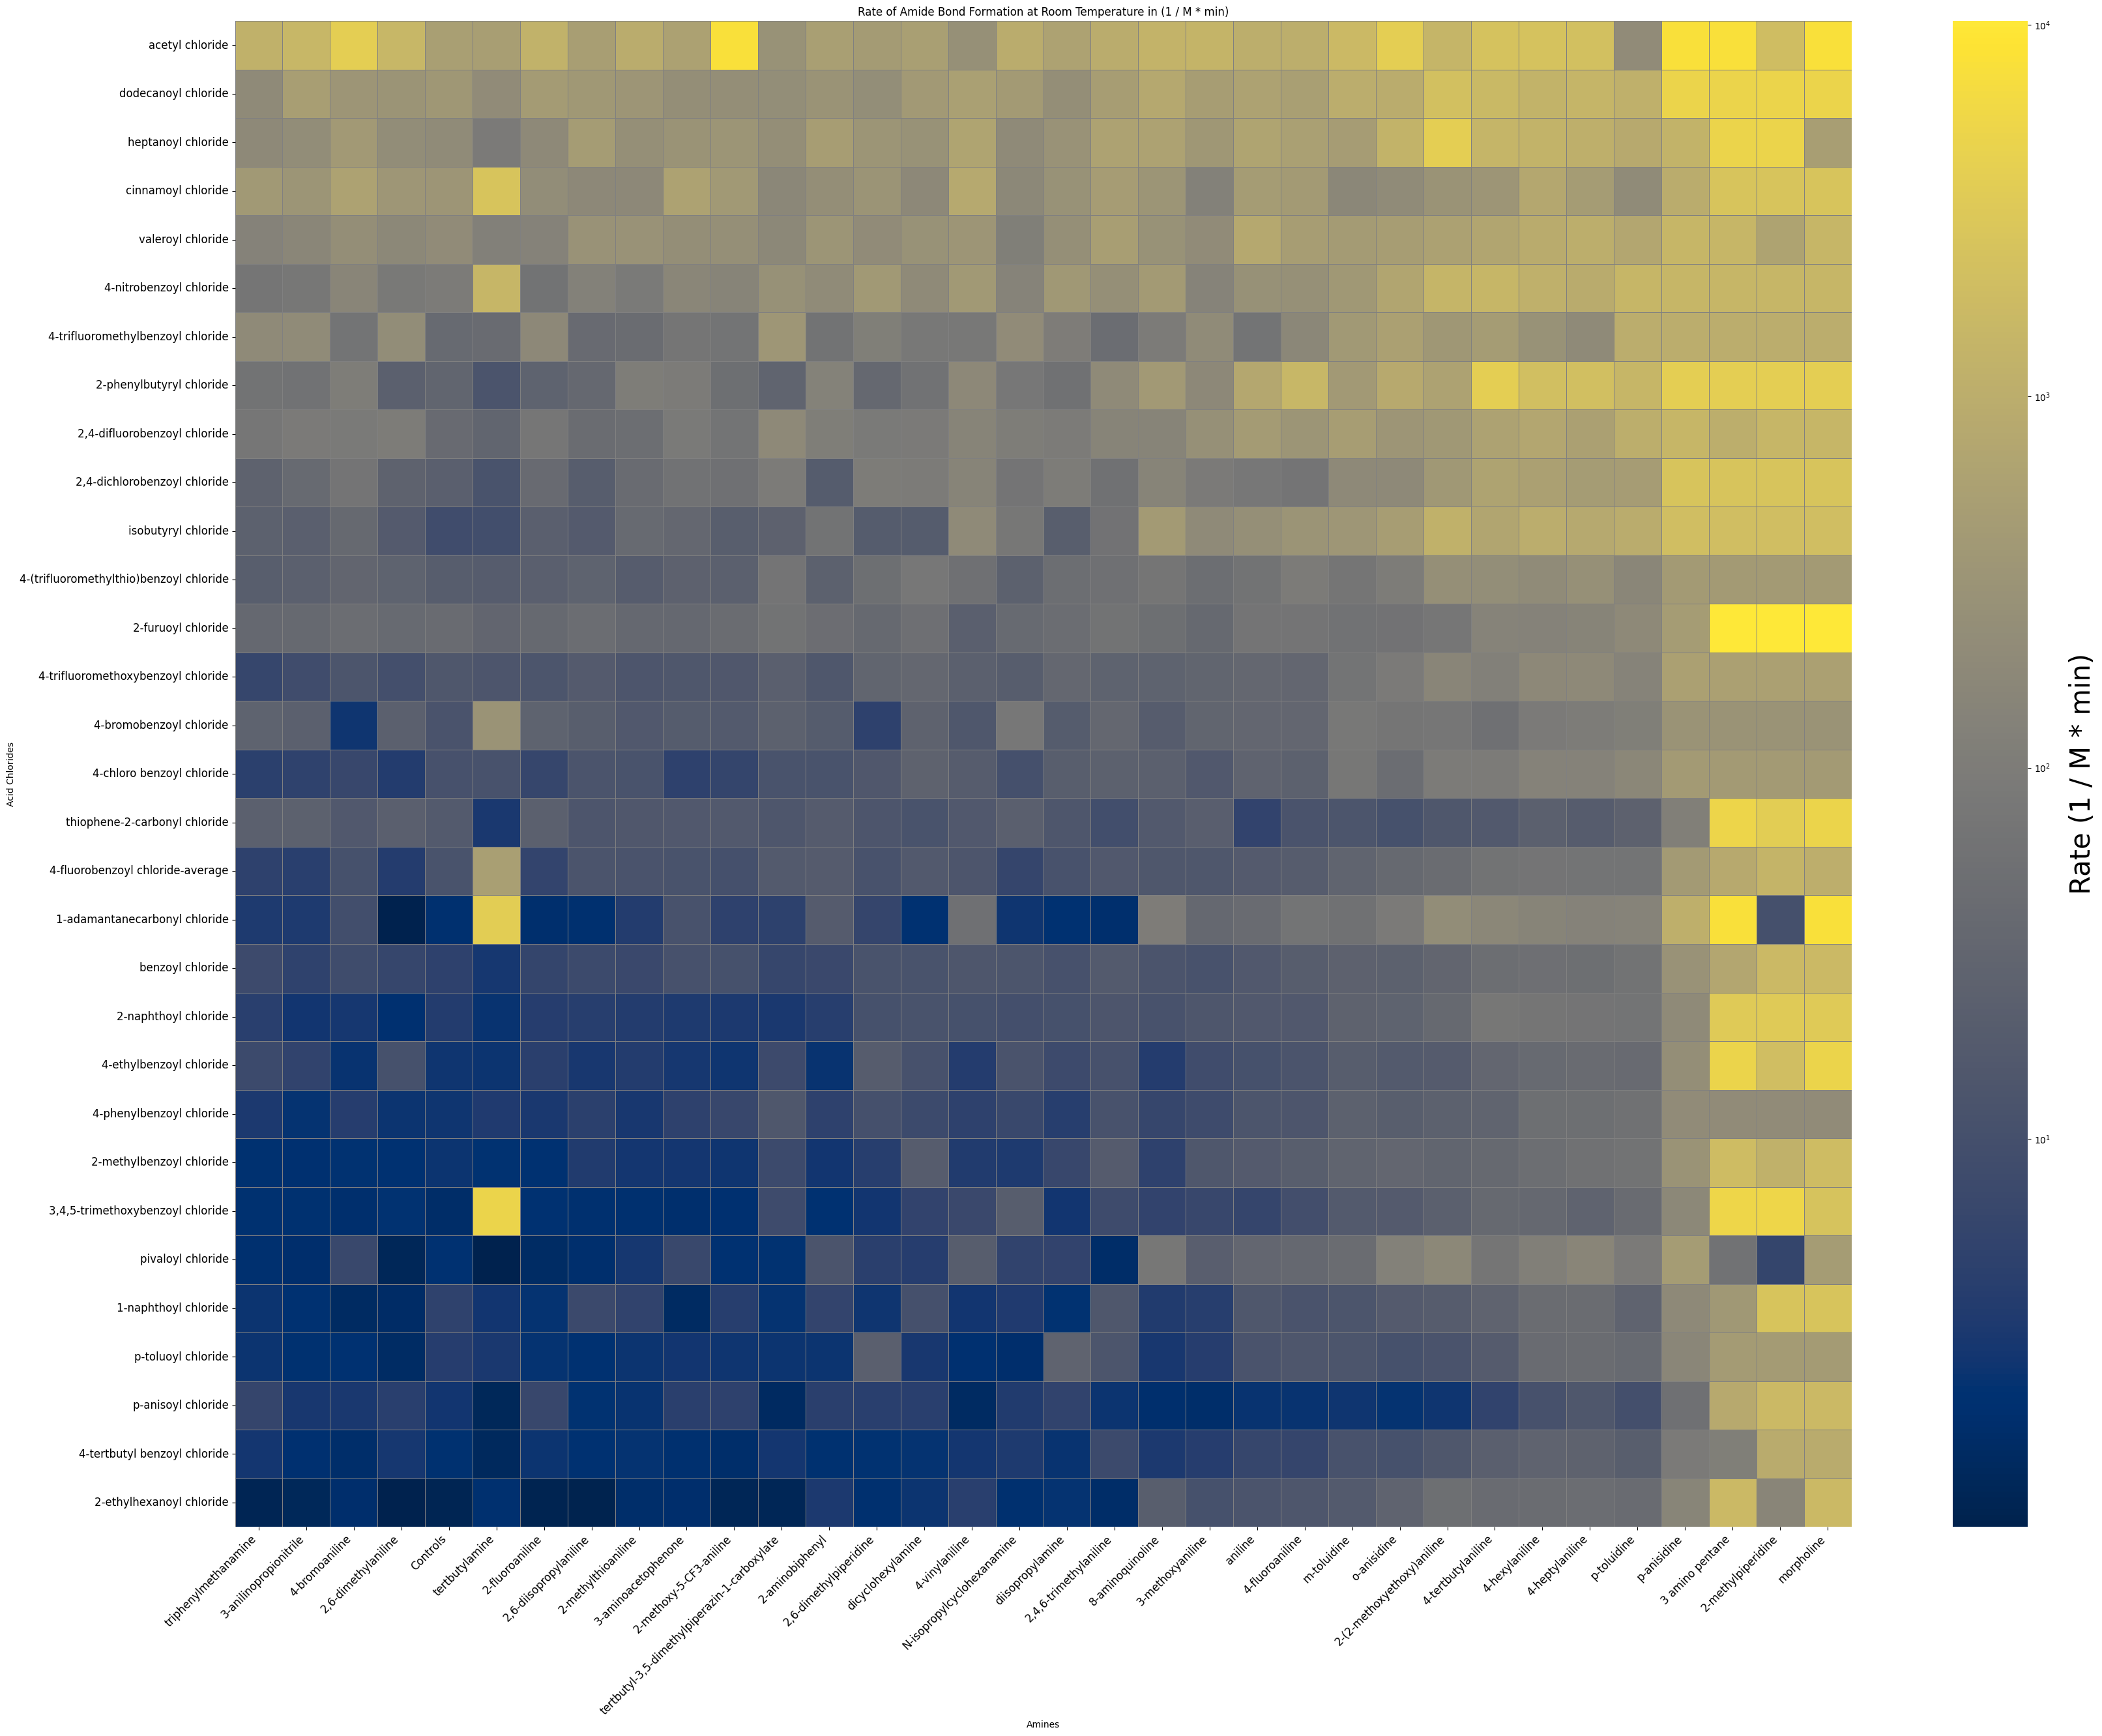

In [9]:
rate_heatmap(sorted_final)